χ² = 22.52 | gl = 4 | p = 0.00016
Inércia total = 0.0563 | V de Cramér = 0.168

Perfis-linha (%):
             D     E     F
Ideal    50.0  33.3  16.7
Premium  26.7  46.7  26.7
Good     28.6  42.9  28.6 

Perfis-coluna (%):
             D     E     F
Ideal    60.0  37.5  33.3
Premium  26.7  43.8  44.4
Good     13.3  18.8  22.2 

Massas linha: {'Ideal': 0.45, 'Premium': 0.375, 'Good': 0.175}
Massas coluna: {'D': 0.375, 'E': 0.4, 'F': 0.225} 

       Valor singular  Autovalor (inércia)  % variância  % acumulada
Dim 1          0.2359               0.0557      98.8743      98.8743
Dim 2          0.0252               0.0006       1.1257     100.0000 



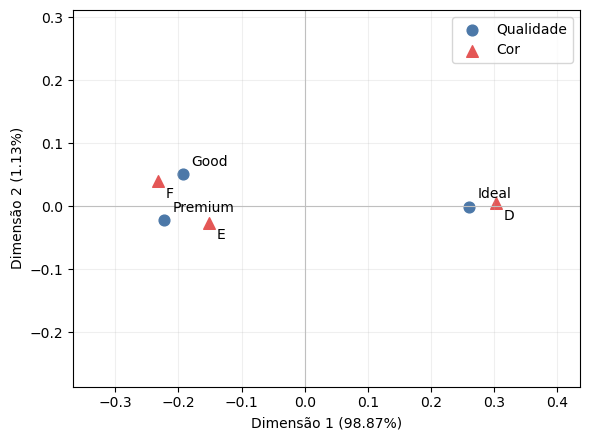

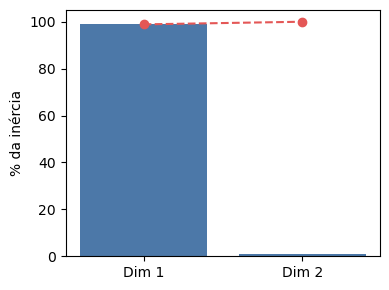

                   Coord 1  Coord 2  cos² D1  cos² D2  Ctr 1 (%)  Ctr 2 (%)
Variável  Nível                                                            
Qualidade Ideal      0.261   -0.001    1.000    0.000     54.893      0.107
          Premium   -0.223   -0.022    0.990    0.010     33.437     29.063
          Good      -0.193    0.051    0.935    0.065     11.670     70.830
Cor       D          0.302    0.004    1.000    0.000     61.441      1.059
          E         -0.152   -0.026    0.971    0.029     16.616     43.384
          F         -0.233    0.040    0.972    0.028     21.943     55.557


In [14]:
import numpy as np
import pandas as pd
import prince
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

dados = pd.DataFrame(
    {'D': [90, 40, 20], 'E': [60, 70, 30], 'F': [30, 40, 20]},
    index=['Ideal', 'Premium', 'Good']
)

# 1. Associação: qui-quadrado, inércia total e V de Cramér
chi2, p, gl, esperado = chi2_contingency(dados)
n = dados.to_numpy().sum()
inercia_total = chi2 / n
cramer_v = np.sqrt(chi2 / (n * (min(dados.shape) - 1)))
print(f"χ² = {chi2:.2f} | gl = {gl} | p = {p:.5f}")
print(f"Inércia total = {inercia_total:.4f} | V de Cramér = {cramer_v:.3f}\n")

# 2. Perfis e massas
print("Perfis-linha (%):\n", (dados.div(dados.sum(axis=1), axis=0) * 100).round(1), "\n")
print("Perfis-coluna (%):\n", (dados.div(dados.sum(axis=0), axis=1) * 100).round(1), "\n")
print("Massas linha:", (dados.sum(axis=1) / n).round(3).to_dict())
print("Massas coluna:", (dados.sum(axis=0) / n).round(3).to_dict(), "\n")

# 3. Valores singulares (SVD dos resíduos padronizados)
P = dados.to_numpy() / n
r, c = P.sum(axis=1), P.sum(axis=0)
S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
sv = np.linalg.svd(S, compute_uv=False)[:2]   # só 2 dimensões existem
autovalores = sv**2                            # inércia principal por dimensão

ca = prince.CA(n_components=2).fit(dados)
prop = np.array(ca.percentage_of_variance_)
acum = np.cumsum(prop)

tabela_sv = pd.DataFrame({
    "Valor singular": sv,
    "Autovalor (inércia)": autovalores,
    "% variância": prop,
    "% acumulada": acum,
}, index=["Dim 1", "Dim 2"]).round(4)
print(tabela_sv, "\n")
# conferência: np.allclose(ca.svd_.s, sv) deve ser True

# 4. Coordenadas
row_coords = ca.row_coordinates(dados)
col_coords = ca.column_coordinates(dados)

# 5. Mapa simétrico
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(row_coords[0], row_coords[1], color="#4C78A8", marker="o", s=60, label="Qualidade")
ax.scatter(col_coords[0], col_coords[1], color="#E45756", marker="^", s=70, label="Cor")
for rot, lin in row_coords.iterrows():
    ax.annotate(rot, (lin[0], lin[1]), xytext=(6, 6), textcoords="offset points")
for rot, col in col_coords.iterrows():
    ax.annotate(rot, (col[0], col[1]), xytext=(6, -12), textcoords="offset points")
ax.axhline(0, color="0.75", lw=0.8); ax.axvline(0, color="0.75", lw=0.8)
ax.set_xlabel(f"Dimensão 1 ({prop[0]:.2f}%)")
ax.set_ylabel(f"Dimensão 2 ({prop[1]:.2f}%)")
ax.set_aspect("equal", adjustable="datalim")
ax.margins(0.25)
ax.grid(alpha=0.2); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# 6. Scree plot
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["Dim 1", "Dim 2"], prop, color="#4C78A8")
ax.plot(["Dim 1", "Dim 2"], acum, "o--", color="#E45756")
ax.set_ylabel("% da inércia"); plt.tight_layout(); plt.show()

# 7. Qualidade (cos²) e contribuições, por dimensão
cos2_r = ca.row_cosine_similarities(dados)
cos2_c = ca.column_cosine_similarities(dados)
ctr_r, ctr_c = ca.row_contributions_, ca.column_contributions_

resultado = pd.DataFrame({
    "Variável": ["Qualidade"] * 3 + ["Cor"] * 3,
    "Nível": list(dados.index) + list(dados.columns),
    "Coord 1": list(row_coords[0]) + list(col_coords[0]),
    "Coord 2": list(row_coords[1]) + list(col_coords[1]),
    "cos² D1": list(cos2_r[0]) + list(cos2_c[0]),
    "cos² D2": list(cos2_r[1]) + list(cos2_c[1]),
    "Ctr 1 (%)": list(ctr_r[0] * 100) + list(ctr_c[0] * 100),
    "Ctr 2 (%)": list(ctr_r[1] * 100) + list(ctr_c[1] * 100),
}).set_index(["Variável", "Nível"]).round(3)
print(resultado)